# TFIA Star


In [ ]:
import heapq, math
import numpy as np
import pandas as pd
from scipy.spatial import cKDTree
from shapely import voronoi_polygons
from shapely.geometry import Point, MultiPoint, LineString, box
from shapely.prepared import prep
from shapely.strtree import STRtree
import matplotlib.pyplot as plt
from shapely.plotting import plot_polygon

KN = 0.5144  


def blue_noise(water, n, rng, max_tries=200_000):
    minx, miny, maxx, maxy = water.bounds
    r = 0.7 * math.sqrt(water.area / n)
    pw = prep(water)
    pts = []

    for _ in range(max_tries):
        p = np.array([rng.uniform(minx, maxx), rng.uniform(miny, maxy)])

        if not pw.contains(Point(p)):
            continue

        if pts and np.min(np.hypot(*(np.array(pts) - p).T)) < r:
            continue

        pts.append(p)

        if len(pts) == n:
            break

    return np.array(pts)


def build_cells(water, seeds):
    vor = voronoi_polygons(MultiPoint([tuple(s) for s in seeds]), extend_to=water)
    polys = list(vor.geoms)
    tree = STRtree(polys)
    cells = []
    kept_seeds = []

    for s in seeds:
        hit = tree.query(Point(s), predicate="within")

        if len(hit) == 0:
            continue

        c = polys[hit[0]].intersection(water)

        if c.is_empty:
            continue

        if c.geom_type == "MultiPolygon":
            c = max(c.geoms, key=lambda g: (g.contains(Point(s)), g.area))

        if c.geom_type != "Polygon":
            continue

        cells.append(c)
        kept_seeds.append(s)

    return cells, np.array(kept_seeds)


def adjacency(cells):
    tree, adj = STRtree(cells), {i: {} for i in range(len(cells))}

    for i, c in enumerate(cells):
        for j in tree.query(c, predicate="intersects"):
            if j <= i:
                continue
            shared = c.intersection(cells[j])
            if shared.length > 1e-9:
                m = shared.representative_point()
                adj[i][j] = adj[j][i] = (m.x, m.y)

    return adj


def find_waypoints(g, sog_rng=(5, 15), ncd_thr=10, snsd_rng=(0, 8)):
    """g: one ship's points in one cell, sorted by time. x,y in km, t in s."""
    if len(g) < 3:
        return np.empty((0, 2))

    x, y, t, cog, sog = (g[c].to_numpy(float) for c in ("x", "y", "t", "cog", "sog"))

    ncd = np.abs((cog[1:-1] - cog[:-2] + 180) % 360 - 180)
    dt = np.maximum(t[2:] - t[:-2], 1e-6)
    ns = np.hypot(x[2:] - x[:-2], y[2:] - y[:-2]) * 1000 / dt
    snsd = np.abs(ns - sog[1:-1] * KN)
    s = sog[1:-1]

    ok = ((s >= sog_rng[0]) & (s <= sog_rng[1])
          & (ncd >= ncd_thr)
          & (snsd >= snsd_rng[0]) & (snsd <= snsd_rng[1]))

    return np.c_[x[1:-1][ok], y[1:-1][ok]]


def fused_node(center, pts, w_density=1.0, w_center=1.0):
    if pts.empty:
        return center

    density = pts[["x", "y"]].mean().to_numpy()
    num = w_density * density + w_center * center
    den = w_density + w_center
    n_tot = len(pts)

    for _, g in pts.groupby("mmsi"):
        wps = find_waypoints(g.sort_values("t"))
        w = len(g) / n_tot
        num = num + w * wps.sum(axis=0) if len(wps) else num
        den += w * len(wps)

    return num / den


def tfia_star(water, ais, start, goal, n_seeds=500, ais_thr=500, seed=0):
    rng = np.random.default_rng(seed)
    cells, seeds = build_cells(water, blue_noise(water, n_seeds, rng))
    adj = adjacency(cells)
    start = np.asarray(start, float)
    goal = np.asarray(goal, float)

    owner = cKDTree(seeds).query(ais[["x", "y"]].to_numpy())[1]
    ais = ais.assign(cell=owner)
    counts = np.bincount(owner, minlength=len(cells))

    s_cell = next(i for i, c in enumerate(cells) if c.contains(Point(start)))
    g_cell = next(i for i, c in enumerate(cells) if c.contains(Point(goal)))

    keep = {i for i in range(len(cells))
            if i in (s_cell, g_cell) or (counts[i] >= ais_thr and len(adj[i]) > 1)}

    groups = dict(tuple(ais.groupby("cell")))
    node = {}

    for i in keep:
        p = fused_node(np.array(cells[i].centroid.coords[0]),
                       groups.get(i, ais.iloc[0:0]))

        if not cells[i].contains(Point(p)):
            q = cells[i].representative_point()
            p = np.array([q.x, q.y])
        node[i] = p

    node[s_cell] = start
    node[g_cell] = goal

    pw = prep(water)

    def leg(i, j):
        a, b = node[i], node[j]
        if pw.contains(LineString([a, b])):
            return [a, b]
        m = np.array(adj[i][j])
        return [a, m, b]

    def length(pl):
        return sum(np.hypot(*(pl[k + 1] - pl[k])) for k in range(len(pl) - 1))

    h = lambda i: float(np.hypot(*(node[i] - goal)))
    openq = [(h(s_cell), s_cell)]
    g = {s_cell: 0.0}
    parent = {}
    closed = set()

    while openq:
        _, u = heapq.heappop(openq)

        if u in closed:
            continue

        if u == g_cell:
            ids = [u]
            while ids[-1] in parent:
                ids.append(parent[ids[-1]])
            ids.reverse()
            path = [node[ids[0]]]
            for a, b in zip(ids, ids[1:]):
                path += leg(a, b)[1:]
            return np.array(path), g[u], len(closed)

        closed.add(u)

        for v in adj[u]:
            if v not in keep or v in closed:
                continue

            ng = g[u] + length(leg(u, v))

            if ng < g.get(v, math.inf):
                g[v] = ng
                parent[v] = u
                heapq.heappush(openq, (ng + h(v), v))

    return None, math.inf, len(closed)


if __name__ == "__main__":
    rng = np.random.default_rng(1)
    water = box(0, 0, 300, 300).difference(box(120, 100, 180, 200))

    def lane(y0, n):
        return pd.DataFrame({
            "mmsi": rng.integers(0, 40, n),
            "t":    rng.uniform(0, 8.6e4, n),
            "x":    rng.uniform(0, 300, n),
            "y":    y0 + rng.normal(0, 5, n),
            "cog":  90 + rng.normal(0, 8, n),
            "sog":  rng.uniform(8, 14, n),
        })

    ais = pd.concat([lane(250, 20_000), lane(30, 20_000)], ignore_index=True)

    path, cost, visited = tfia_star(water, ais, (10, 20), (290, 40),
                                    n_seeds=200, ais_thr=50)

    print(cost, visited, None if path is None else len(path))

287.24251486892723 20 14


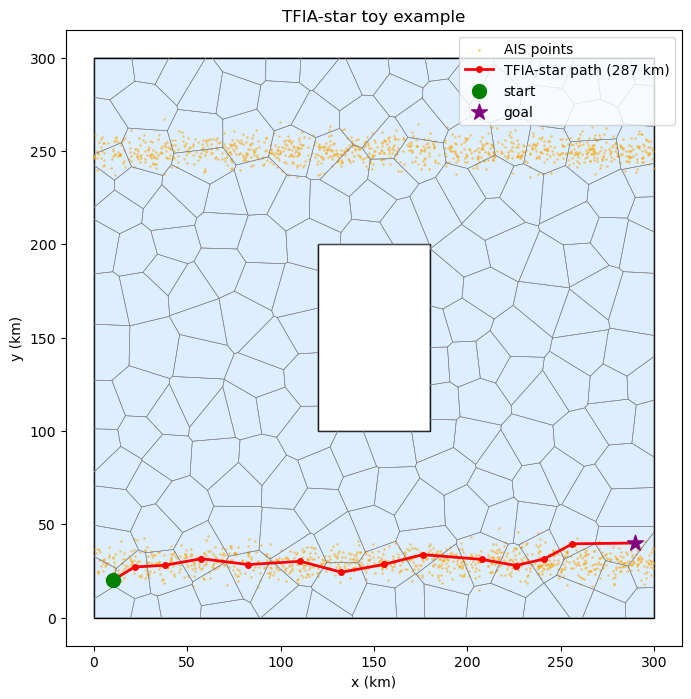

In [133]:
import matplotlib.pyplot as plt
from shapely.plotting import plot_polygon


rng0 = np.random.default_rng(0)
cells, seeds = build_cells(water, blue_noise(water, 200, rng0))

fig, ax = plt.subplots(figsize=(8, 8))
plot_polygon(water, ax=ax, add_points=False, facecolor="#dceeff", edgecolor="black")

for c in cells:
    ax.plot(*c.exterior.xy, color="gray", lw=0.4)

ax.scatter(ais.x[::20], ais.y[::20], s=1, c="orange", alpha=0.4, label="AIS points")
ax.plot(path[:, 0], path[:, 1], "r-o", ms=4, lw=2, label=f"TFIA-star path ({cost:.0f} km)")
ax.scatter(*(10, 20), c="green", s=100, zorder=5, label="start")
ax.scatter(*(290, 40), c="purple", s=140, marker="*", zorder=5, label="goal")

ax.set_aspect("equal")
ax.set_xlabel("x (km)"); ax.set_ylabel("y (km)")
ax.set_title("TFIA-star toy example")
ax.legend(loc="upper right")
plt.show()